# AgentWeather: Exploratory Data Analysis
Lahore, hourly data from the Hopsworks feature store (`weather_features` v3). Timestamps are Lahore local time stored labeled as UTC.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)

sys.path.insert(0, str(Path.cwd().parent))

plt.rcParams["figure.dpi"] = 110
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

In [2]:
from ingestion.store import get_feature_group, get_feature_store

df = get_feature_group(get_feature_store()).read()
df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(None)
df = df.sort_values("time").reset_index(drop=True)
df.shape

2026-11-16 20:04:09,854 INFO: Initializing external client
2026-11-16 20:04:09,857 INFO: Base URL: https://eu-west.cloud.hopsworks.ai:443



Logged in to project, explore it here https://eu-west.cloud.hopsworks.ai:443/p/57472


2026-11-16 20:04:16,719 INFO: Python Engine initialized.


Finished: Reading data from Hopsworks, using Hopsworks Feature Query Service (138.88s) 


(25194, 46)

In [3]:
METRICS = {
    "AQI (US)": "us_aqi",
    "Temperature (C)": "temperature_2m",
    "Precipitation (mm)": "precipitation",
    "Humidity (%)": "relative_humidity_2m",
    "UV index": "uv_index",
    "Wind speed (km/h)": "wind_speed_10m",
    "Wind direction (deg)": "wind_direction_10m",
}
TARGETS = {
    "us_aqi": "target_aqi",
    "temperature_2m": "target_temp",
    "precipitation": "target_precip",
    "relative_humidity_2m": "target_humidity",
    "uv_index": "target_uv",
    "wind_speed_10m": "target_wind_speed",
    "wind_direction_10m": "target_wind_dir",
}
LINEAR = [c for c in METRICS.values() if c != "wind_direction_10m"]

## 1. Overview

In [4]:
expected = int((df["time"].max() - df["time"].min()) / pd.Timedelta(hours=1)) + 1
print("range:", df["time"].min(), "->", df["time"].max())
print("rows:", len(df), "| expected hourly rows:", expected)
print("duplicate timestamps:", df["time"].duplicated().sum())
print("rows without target (forecast-only):", df["target_aqi"].isna().sum())
df[list(METRICS.values()) + ["pm10", "pm2_5"]].describe().T

range: 2024-01-02 00:00:00 -> 2026-11-16 17:00:00
rows: 25194 | expected hourly rows: 25194
duplicate timestamps: 0
rows without target (forecast-only): 24


,count,mean,std,min,25%,50%,75%,max
us_aqi,25194.0,151.916567,48.484140,56.0,116.0,152.0,175.0,538.0
temperature_2m,25194.0,24.500583,8.575040,2.7,18.3,26.1,30.7,46.5
precipitation,25194.0,0.088291,0.691866,0.0,0.0,0.0,0.0,19.9
relative_humidity_2m,25194.0,63.592562,23.006169,5.0,46.0,67.0,83.0,100.0
uv_index,25194.0,1.290793,2.109253,0.0,0.0,0.0,1.9,10.6
wind_speed_10m,25194.0,6.393614,3.871984,0.0,3.7,5.7,8.3,36.7
wind_direction_10m,25194.0,178.723903,108.798598,1.0,87.0,149.0,290.0,360.0
pm10,25194.0,99.096983,72.348544,3.6,52.6,78.9,123.9,890.3
pm2_5,25194.0,68.277213,48.927707,3.4,35.3,53.1,83.8,365.1


## 2. Missingness and imputation

rows with any imputed value: 0 (0.00%)
max imputed values in one row: 0
nulls in base columns:
us_aqi                  0
temperature_2m          0
precipitation           0
relative_humidity_2m    0
uv_index                0
wind_speed_10m          0
wind_direction_10m      0
pm10                    0
pm2_5                   0
dtype: int64


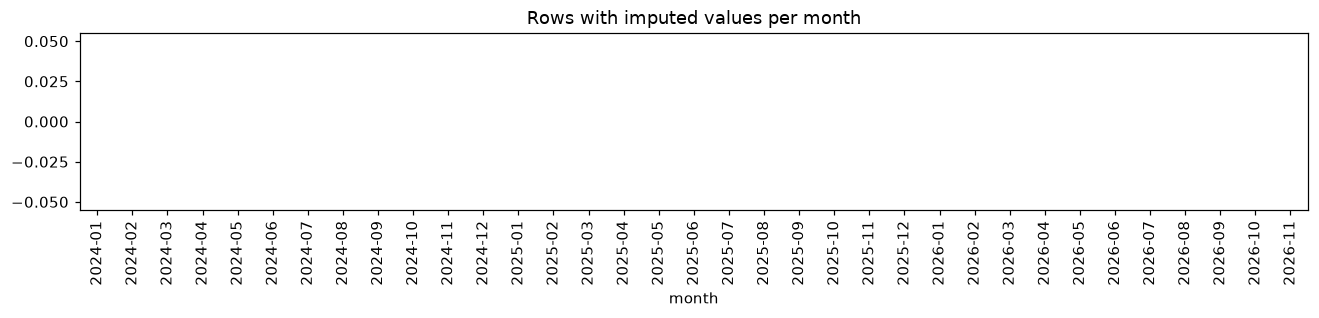

In [5]:
imp = df["n_imputed"] > 0
print(f"rows with any imputed value: {imp.sum()} ({imp.mean() * 100:.2f}%)")
print("max imputed values in one row:", df["n_imputed"].max())
print("nulls in base columns:")
print(df[list(METRICS.values()) + ["pm10", "pm2_5"]].isna().sum())
monthly = df.assign(month=df["time"].dt.to_period("M")).groupby("month")["n_imputed"].apply(lambda s: int((s > 0).sum()))
monthly.plot(kind="bar", figsize=(12, 3), title="Rows with imputed values per month")
plt.tight_layout()
plt.savefig(FIG / "missingness.png")

## 3. Distributions

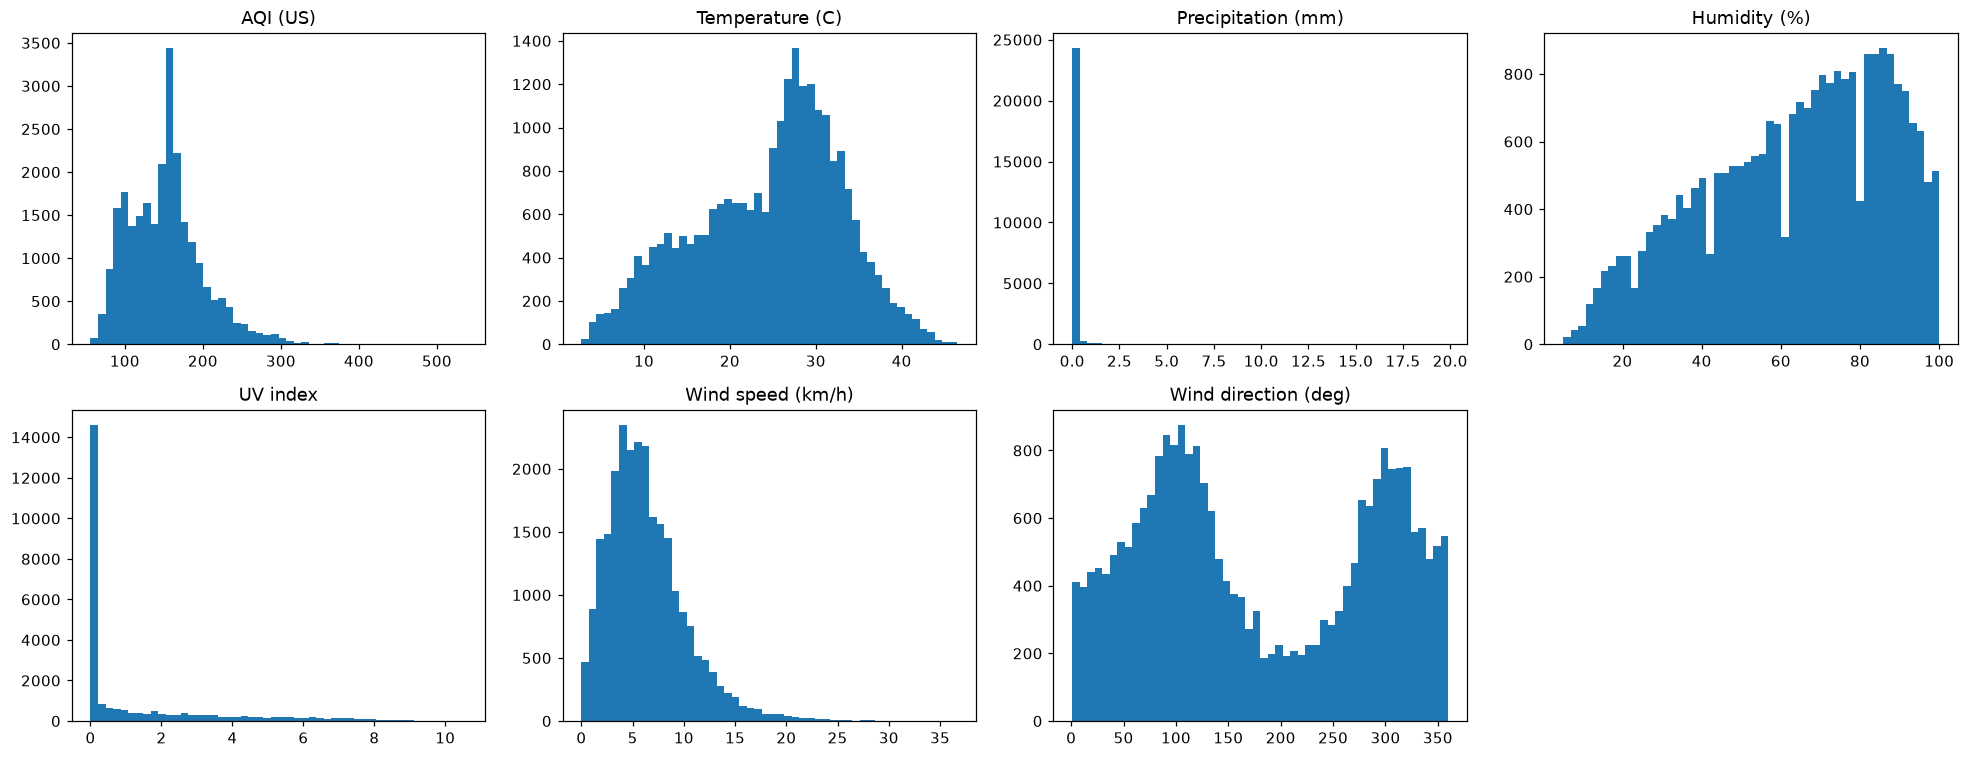

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (name, col) in zip(axes.ravel(), METRICS.items()):
    ax.hist(df[col].dropna(), bins=50)
    ax.set_title(name)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG / "distributions.png")

## 4. Trend over time (daily means)

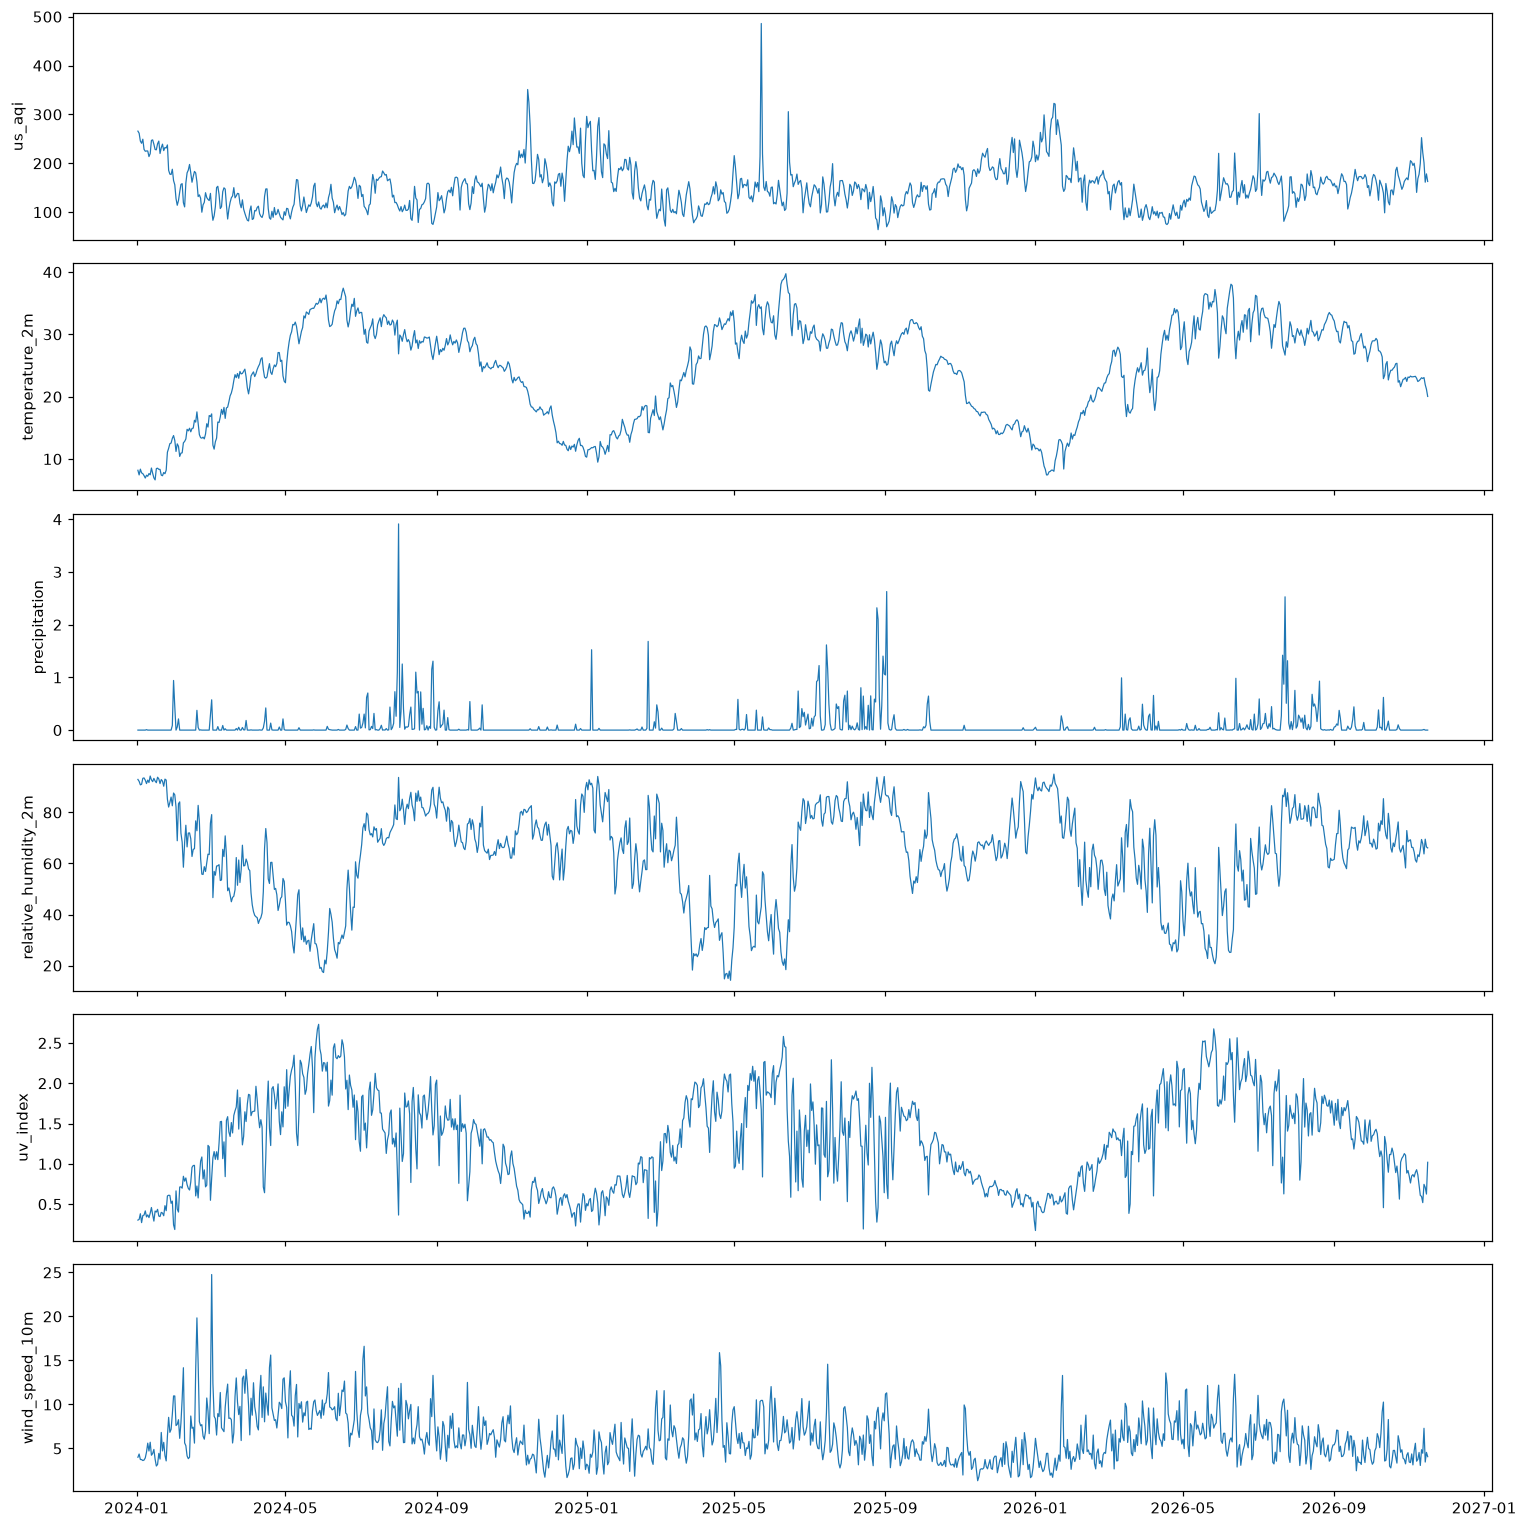

In [7]:
daily = df.set_index("time")[LINEAR].resample("D").mean()
fig, axes = plt.subplots(len(LINEAR), 1, figsize=(14, 14), sharex=True)
for ax, col in zip(axes, LINEAR):
    ax.plot(daily.index, daily[col], linewidth=0.8)
    ax.set_ylabel(col)
plt.tight_layout()
plt.savefig(FIG / "daily_trend.png")

## 5. Seasonality: time of day and month

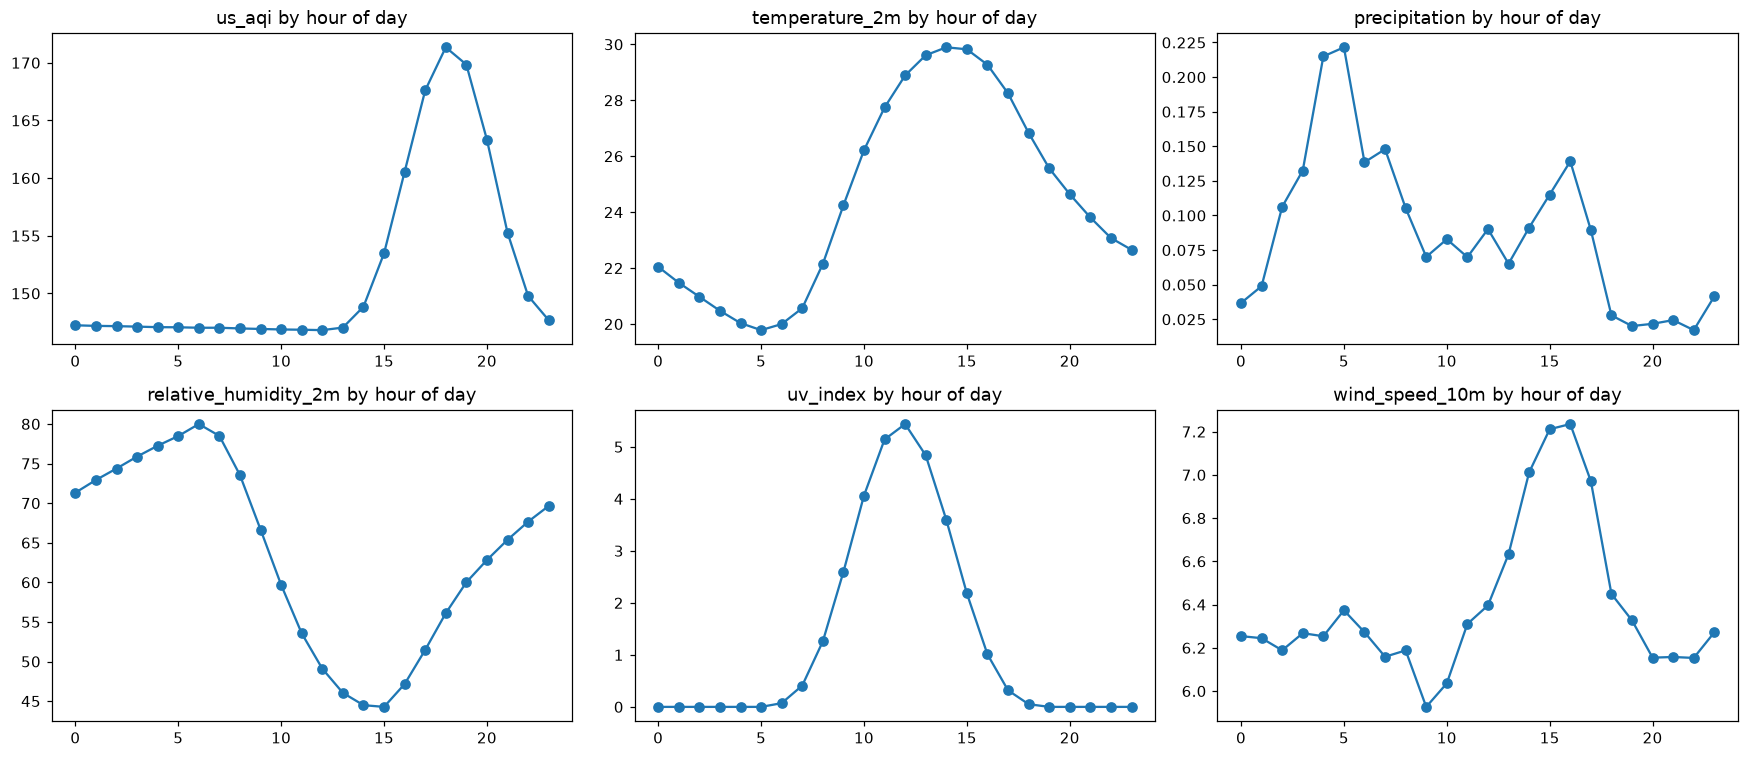

In [8]:
hourly = df.groupby(df["time"].dt.hour)[LINEAR].mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.ravel(), LINEAR):
    ax.plot(hourly.index, hourly[col], marker="o")
    ax.set_title(f"{col} by hour of day")
plt.tight_layout()
plt.savefig(FIG / "hourly_profile.png")

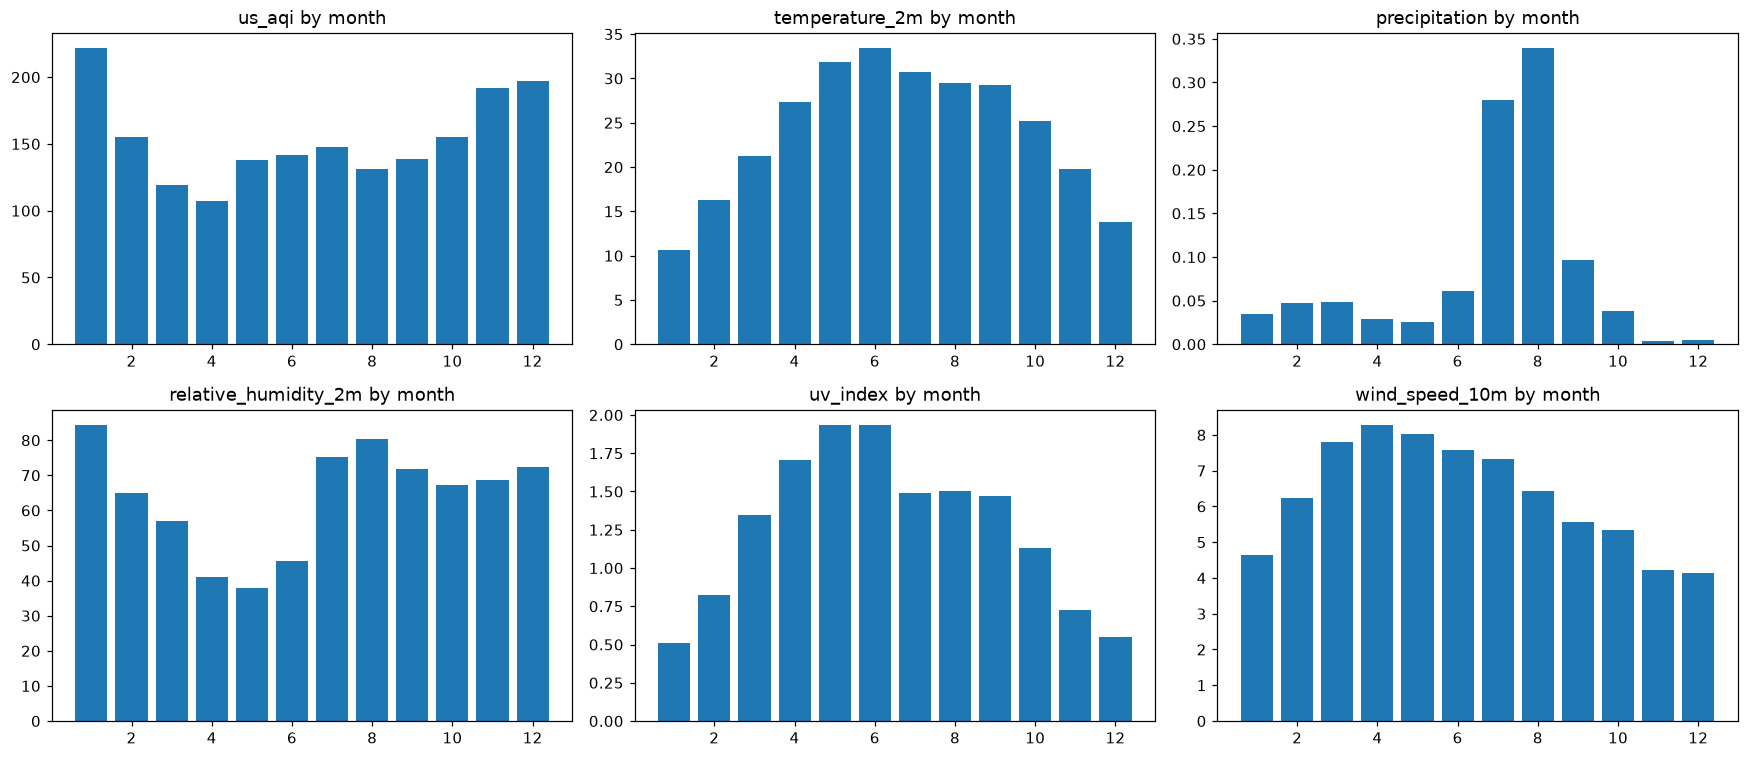

In [9]:
monthly = df.groupby(df["time"].dt.month)[LINEAR].mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.ravel(), LINEAR):
    ax.bar(monthly.index, monthly[col])
    ax.set_title(f"{col} by month")
plt.tight_layout()
plt.savefig(FIG / "monthly_profile.png")

## 6. AQI deep dive

us_aqi
Good                      0.00
Moderate                 15.34
Unhealthy (sensitive)    31.83
Unhealthy                39.49
Very unhealthy           12.54
Hazardous                 0.80
Name: proportion, dtype: float64


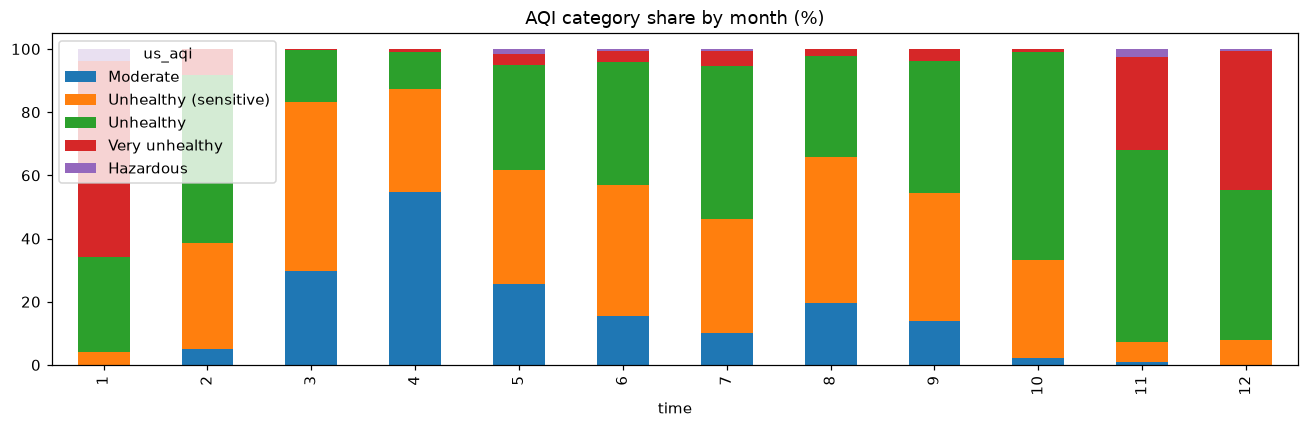

In [10]:
labels = ["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy", "Very unhealthy", "Hazardous"]
bands = pd.cut(df["us_aqi"], [-1, 50, 100, 150, 200, 300, 10000], labels=labels)
print((bands.value_counts(normalize=True).reindex(labels) * 100).round(2))
by_month = pd.crosstab(df["time"].dt.month, bands, normalize="index") * 100
by_month.plot(kind="bar", stacked=True, figsize=(12, 4), title="AQI category share by month (%)")
plt.tight_layout()
plt.savefig(FIG / "aqi_bands_by_month.png")

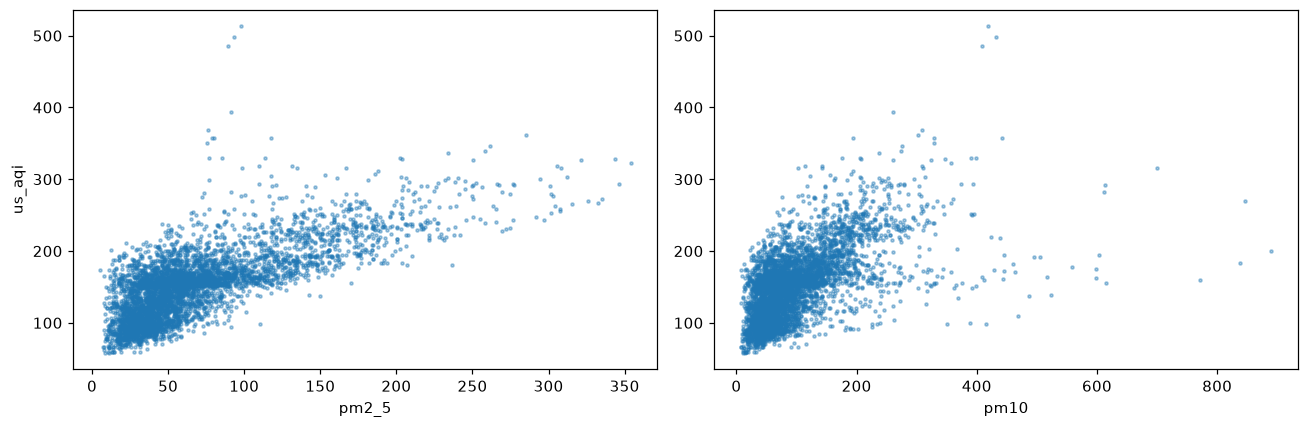

In [11]:
sample = df.sample(min(5000, len(df)), random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sample["pm2_5"], sample["us_aqi"], s=4, alpha=0.4)
axes[0].set_xlabel("pm2_5")
axes[0].set_ylabel("us_aqi")
axes[1].scatter(sample["pm10"], sample["us_aqi"], s=4, alpha=0.4)
axes[1].set_xlabel("pm10")
plt.tight_layout()
plt.savefig(FIG / "aqi_vs_pm.png")

## 7. Precipitation and rain

rain hours: 1914 (7.60%)
count    1914.000000
mean        1.162173
std         2.248380
min         0.100000
25%         0.100000
50%         0.300000
75%         1.100000
max        19.900000
Name: precipitation, dtype: float64


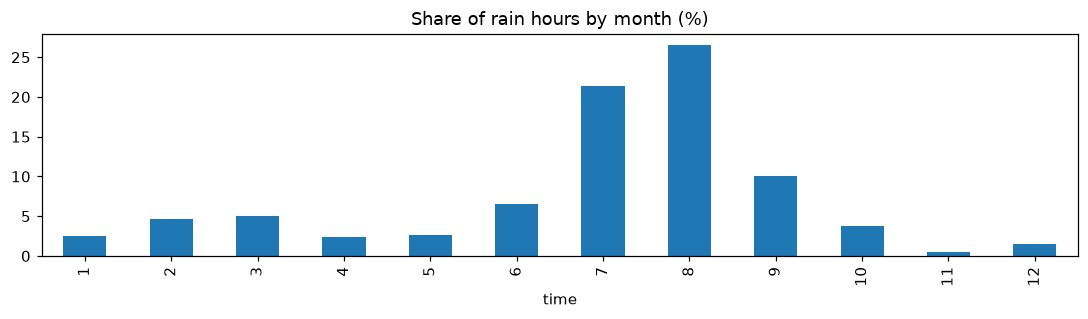

In [12]:
rain = df["precipitation"] >= 0.1
print(f"rain hours: {rain.sum()} ({rain.mean() * 100:.2f}%)")
print(df.loc[rain, "precipitation"].describe())
share = rain.groupby(df["time"].dt.month).mean() * 100
share.plot(kind="bar", figsize=(10, 3), title="Share of rain hours by month (%)")
plt.tight_layout()
plt.savefig(FIG / "rain_by_month.png")

## 8. Wind

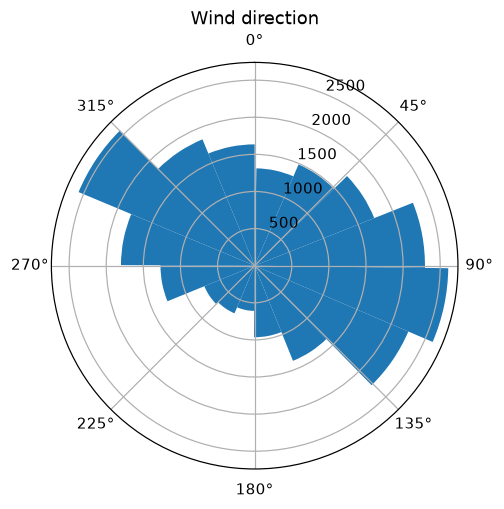

In [13]:
ang = np.deg2rad(df["wind_direction_10m"].dropna())
ax = plt.subplot(projection="polar")
ax.hist(ang, bins=16)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_title("Wind direction")
plt.savefig(FIG / "wind_rose.png")

## 9. Correlations

,us_aqi,temperature_2m,precipitation,relative_humidity_2m,uv_index,wind_speed_10m,wind_direction_10m,pm10,pm2_5
us_aqi,1.00,-0.35,-0.07,0.26,-0.20,-0.28,-0.01,0.59,0.74
temperature_2m,-0.35,1.00,0.01,-0.59,0.45,0.20,-0.08,-0.21,-0.57
precipitation,-0.07,0.01,1.00,0.14,-0.02,0.13,-0.06,-0.05,-0.07
relative_humidity_2m,0.26,-0.59,0.14,1.00,-0.43,-0.19,-0.23,0.23,0.47
uv_index,-0.20,0.45,-0.02,-0.43,1.00,0.07,0.06,-0.11,-0.28
wind_speed_10m,-0.28,0.20,0.13,-0.19,0.07,1.00,-0.04,-0.11,-0.36
wind_direction_10m,-0.01,-0.08,-0.06,-0.23,0.06,-0.04,1.00,-0.13,-0.06
pm10,0.59,-0.21,-0.05,0.23,-0.11,-0.11,-0.13,1.00,0.74
pm2_5,0.74,-0.57,-0.07,0.47,-0.28,-0.36,-0.06,0.74,1.00


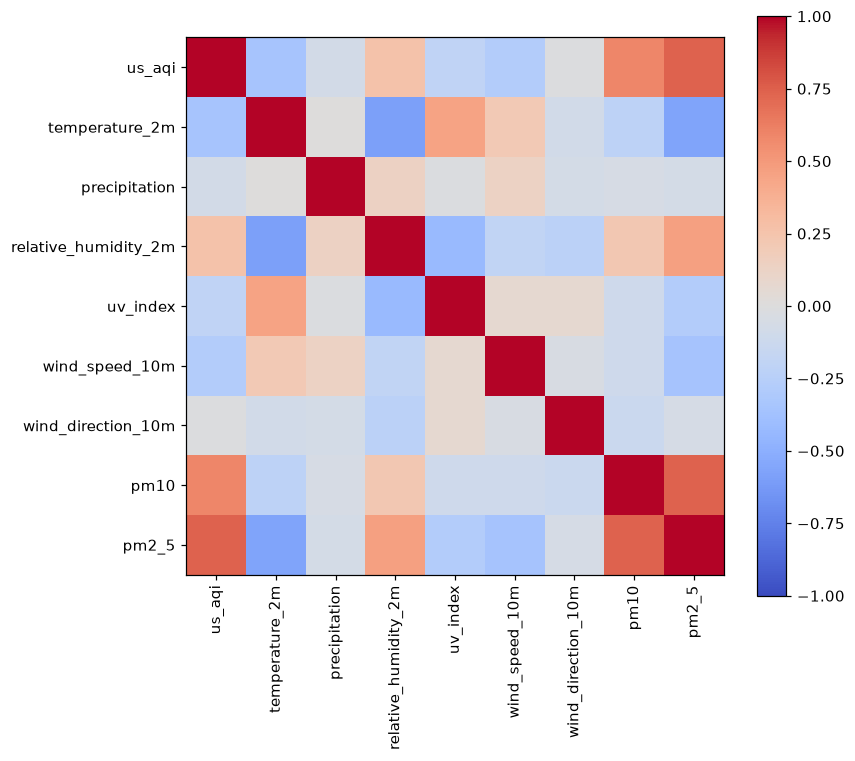

In [14]:
cols = list(METRICS.values()) + ["pm10", "pm2_5"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
fig.colorbar(im)
plt.tight_layout()
plt.savefig(FIG / "correlation.png")
corr.round(2)

## 10. Outliers

In [15]:
rows = []
for name, col in METRICS.items():
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    n = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    rows.append({"metric": name, "min": s.min(), "max": s.max(), "iqr_outliers": n, "share_pct": round(n / len(s) * 100, 2)})
pd.DataFrame(rows)

,metric,min,max,iqr_outliers,share_pct
0,AQI (US),56.0,538.0,643,2.55
1,Temperature (C),2.7,46.5,0,0.00
2,Precipitation (mm),0.0,19.9,1914,7.60
3,Humidity (%),5.0,100.0,0,0.00
4,UV index,0.0,10.6,2556,10.15
5,Wind speed (km/h),0.0,36.7,729,2.89
6,Wind direction (deg),1.0,360.0,0,0.00


## 11. Naive baseline preview
The forecast for t+24h is the value at t. Time-based split: first 80% of labeled rows train, last 20% test. These are the scores every model has to beat.

In [16]:
labeled = df.dropna(subset=list(TARGETS.values())).reset_index(drop=True)
cut = int(len(labeled) * 0.8)
test = labeled.iloc[cut:]
print("train rows:", cut, "| test rows:", len(test), "| test starts:", test["time"].min())

def ang_diff(a, b):
    return (a - b + 180) % 360 - 180

rows = []
for name, col in METRICS.items():
    y, p = test[TARGETS[col]], test[col]
    if col == "wind_direction_10m":
        d = ang_diff(p, y)
        rows.append({"metric": name, "RMSE": np.sqrt((d ** 2).mean()), "MAE": d.abs().mean(), "R2": np.nan})
    else:
        rows.append({"metric": name, "RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)})
baseline = pd.DataFrame(rows)
baseline.round(4)

train rows: 20136 | test rows: 5034 | test starts: 2026-04-20 00:00:00


,metric,RMSE,MAE,R2
0,AQI (US),31.0313,19.9076,0.2578
1,Temperature (C),2.2095,1.5710,0.8121
2,Precipitation (mm),0.9222,0.1781,-0.7778
3,Humidity (%),9.6616,6.9160,0.7979
4,UV index,0.5827,0.2315,0.9413
5,Wind speed (km/h),4.0222,2.9636,-0.4041
6,Wind direction (deg),77.3424,60.4742,NaN


In [17]:
y = test["target_rain"]
p = (test["precipitation"] >= 0.1).astype(float)
print("rain share in test:", round(y.mean() * 100, 2), "%")
print("accuracy:", round((y == p).mean(), 4))
print("precision:", round(precision_score(y, p, zero_division=0), 4))
print("recall:", round(recall_score(y, p, zero_division=0), 4))
print("f1:", round(f1_score(y, p, zero_division=0), 4))
baseline.to_csv(FIG / "naive_baseline.csv", index=False)

rain share in test: 11.18 %
accuracy: 0.8526
precision: 0.341
recall: 0.341
f1: 0.341


## Findings to carry into the report
Write 3 to 5 bullets per metric here after running the notebook: distribution shape, seasonality, outliers, and how the naive baseline performs.